# Example 1.8
 — Multi-objective (Pareto) GA: Simultaneous Optimization

**Four Bar Mechanisms — Design with Genetic Algorithms and Neural Networks**

Open this notebook in Google Colab: [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/usuario/repo/blob/main/ex1_9_ag_multiobjetivo_pareto.ipynb)

In [2]:
from numpy import *
import builtins

# Avoid name conflicts with Python's built-in functions
min = builtins.min
max = builtins.max

random.seed(42)
N_POP, N_GEN   = 80, 50
L_MIN, L_MAX   = 30.0, 200.0
P_MUT, MUT_STD = 0.25, 10.0

def zona_optima(a, b, c, d):
    t2 = linspace(0, 2*pi, 180)
    K1=d/a; K2=d/c; K3=(a**2-b**2+c**2+d**2)/(2*a*c)
    A=cos(t2)-K1-K2*cos(t2)+K3
    B=-2*sin(t2)
    C=K1-(K2+1)*cos(t2)+K3
    disc=B**2-4*A*C; ok=disc>=0
    if not any(ok): return 0.0
    t4=2*arctan2(-B[ok]-sqrt(disc[ok]), 2*A[ok]+1e-12)
    mu=degrees(abs(arccos(clip((b**2+c**2-a**2-d**2
       +2*d*a*cos(t2[ok])-2*c*d*cos(t4))/(2*b*c+1e-12),-1,1))))
    return 100.0*mean((mu>=45)&(mu<=135))

def grashof_ok(ind):
    s,l = min(ind), max(ind)
    return s+l <= (sum(ind)-s-l)

def objetivos(ind):
    if not grashof_ok(ind): return (100.0, sum(ind)*10)
    return (100.0-zona_optima(*ind), sum(ind))

def domina(f1, f2):
    return all(f1<=f2) and any(f1<f2)

def frente_nd(pop, fits):
    n=len(pop); nd=[True]*n
    for i in range(n):
        for j in range(n):
            if i!=j and nd[i] and domina(fits[j],fits[i]):
                nd[i]=False; break
    idx=[i for i in range(n) if nd[i]]
    return array([pop[i] for i in idx]), array([fits[i] for i in idx])

# -- Multi-objective GA --
pop  = random.uniform(L_MIN, L_MAX, (N_POP, 4))
fits = array([objetivos(p) for p in pop])

for gen in range(N_GEN):
    hijos=[]
    for _ in range(N_POP):
        i,j=random.choice(N_POP,2,replace=False)
        if domina(fits[i],fits[j]):    g=i
        elif domina(fits[j],fits[i]):  g=j
        else: g=i if (fits[i][0]+fits[i][1])<(fits[j][0]+fits[j][1]) else j
        h=pop[g].copy()
        if random.rand()<P_MUT: h+=random.randn(4)*MUT_STD
        hijos.append(clip(h, L_MIN, L_MAX))
    hijos=array(hijos); fh=array([objetivos(h) for h in hijos])
    pc=vstack([pop,hijos]); fc=vstack([fits,fh])
    fp,ff=frente_nd(pc,fc)
    nd_set=set(map(tuple,fp.tolist()))
    rest=sorted([(pc[i],fc[i]) for i in range(len(pc))
                 if tuple(pc[i].tolist()) not in nd_set],
                key=lambda x: x[1][0]+x[1][1])
    ext=N_POP-len(fp)
    if ext>0 and rest:
        pop=vstack([fp,array([r[0] for r in rest[:ext]])])[:N_POP]
        fits=vstack([ff,array([r[1] for r in rest[:ext]])])[:N_POP]
    else:
        pop=fp[:N_POP]; fits=ff[:N_POP]

# -- Final front and three representative solutions --
fp,ff=frente_nd(pop,fits)
orden=argsort(ff[:,1]); fp,ff=fp[orden],ff[orden]
seen=set(); fd,sd=[],[]
for i in range(len(fp)):
    k=(round(ff[i,0]/0.5)*0.5, round(ff[i,1]))
    if k not in seen: seen.add(k); fd.append(fp[i]); sd.append(ff[i])
fp=array(fd); ff=array(sd)

ic,ir=0,len(fp)-1
v=array([ff[-1,1],ff[-1,0]])-array([ff[0,1],ff[0,0]])

# Calculate the 2D cross product manually to avoid NumPy 2.0 warnings
d=[]
for i in range(len(fp)):
    diff = array([ff[i,1], ff[i,0]]) - array([ff[0,1], ff[0,0]])
    cross_val = v[0] * diff[1] - v[1] * diff[0]
    d.append(abs(cross_val) / (linalg.norm(v) + 1e-12))
ik=int(argmax(array(d)))

print('Pareto Front: {} non-dominated solutions'.format(len(fp)))
print()
for nm,ix in zip(['Compact','Compromise','Robust'],[ic,ik,ir]):
    a,b,c,dd=fp[ix]; z=100.0-ff[ix,0]; lt=ff[ix,1]
    print('{:<12} Ltot={:6.1f}mm  Zone={:5.1f}%  [{:.1f},{:.1f},{:.1f},{:.1f}]'
          .format(nm,lt,z,a,b,c,dd))

print()
print('  #    a(mm)  b(mm)  c(mm)  d(mm)   Ltot   Zone%')
print('-'*52)
step=max(1,len(fp)//5)
for i,ix in enumerate(range(0,len(fp),step)[:5],1):
    a,b,c,dd=fp[ix]; z=100.0-ff[ix,0]; lt=ff[ix,1]
    print('  {}  {:6.1f} {:6.1f} {:6.1f} {:6.1f}  {:6.1f}  {:5.1f}%'
          .format(i,a,b,c,dd,lt,z))

Pareto Front: 6 non-dominated solutions

Compact      Ltot= 149.5mm  Zone= 74.4%  [43.6,32.0,43.9,30.0]
Compromise   Ltot= 225.3mm  Zone= 85.6%  [81.6,30.0,78.6,35.2]
Robust       Ltot= 244.9mm  Zone=100.0%  [89.4,52.9,72.7,30.0]

  #    a(mm)  b(mm)  c(mm)  d(mm)   Ltot   Zone%
----------------------------------------------------
  1    43.6   32.0   43.9   30.0   149.5   74.4%
  2    49.1   35.3   44.3   30.0   158.7   77.2%
  3    59.6   47.9   42.2   30.0   179.7   79.4%
  4    60.2   41.7   49.5   30.0   181.4   82.2%
  5    81.6   30.0   78.6   35.2   225.3   85.6%


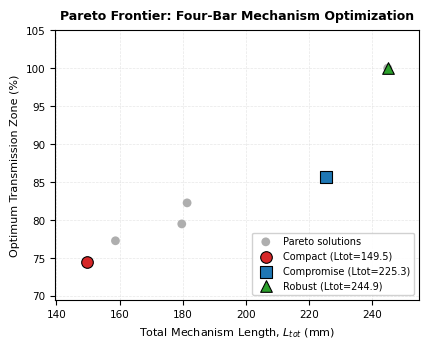

In [5]:
import os
import glob
import matplotlib.pyplot as plt
import numpy as np

# Configure dynamic file naming
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Fig1_9_ga_multiobjective_pareto"
except Exception:
    notebook_name = "Fig1_9_ga_multiobjective_pareto"

# Set Springer editorial style configurations
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

# Get objective functions to plot
# ff[:, 0] represents (100 - %Zone), so Optimum Zone % is 100 - ff[:, 0]
optimum_zones = 100.0 - ff[:, 0]
total_lengths = ff[:, 1]

# Springer single-column width is typically ~4.7 inches
fig, ax = plt.subplots(figsize=(4.7, 3.5))

# Plot Pareto front solutions
ax.scatter(total_lengths, optimum_zones, color='#8c8c8c', alpha=0.7, edgecolors='none', s=40, label='Pareto solutions')

# Highlight representative solutions
ax.scatter(ff[ic, 1], 100.0 - ff[ic, 0], color='#d62728', s=70, marker='o', edgecolors='black', linewidths=0.8, zorder=5, label=f'Compact (Ltot={ff[ic, 1]:.1f})')
ax.scatter(ff[ik, 1], 100.0 - ff[ik, 0], color='#1f77b4', s=70, marker='s', edgecolors='black', linewidths=0.8, zorder=5, label=f'Compromise (Ltot={ff[ik, 1]:.1f})')
ax.scatter(ff[ir, 1], 100.0 - ff[ir, 0], color='#2ca02c', s=70, marker='^', edgecolors='black', linewidths=0.8, zorder=5, label=f'Robust (Ltot={ff[ir, 1]:.1f})')

# Titles and Labels (English, Academic)
ax.set_title('Pareto Frontier: Four-Bar Mechanism Optimization', fontsize=9, fontweight='bold', pad=8)
ax.set_xlabel('Total Mechanism Length, $L_{tot}$ (mm)', fontsize=8)
ax.set_ylabel('Optimum Transmission Zone (%)', fontsize=8)

# Ensure clear padding to prevent markers/labels truncation
ax.set_xlim(min(total_lengths) - 10, max(total_lengths) + 10)
ax.set_ylim(min(optimum_zones) - 5, 105)

# Grid and Tick layout
ax.grid(True, linestyle='--', alpha=0.3, linewidth=0.5)
ax.tick_params(axis='both', which='major', labelsize=7.5)
ax.legend(fontsize=7, loc='lower right', framealpha=0.9)

# Save figures with Springer guidelines
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()